# House Prices: Exploratory Data Analysis
Somtochukwu Kingsley Ekeh

Assignment 2 - Part 3

This analysis explores the supplied training data to describe house prices, examine distributions, and identify variables associated with SalePrice. It does not build a prediction model.

## Exercise 


For this exercise, you will be working with the [House Price Dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/code).

Please grab the train.csv file from Kaggle and explore this dataset. You need to perform explroatory data analysis and see if there is any correlation between the variables and analyze the distribution of the dataset. The question is open-ended and basically you're asked to perform EDA. 


1- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 3 of your assignment, you need to submit at least one jupyter notebook file and one pdf file.


2- Push your code and project to github and provide the link to your code here. Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

- Src
- Data
- Docs
- Results

Read this link for further info:  https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510





## 1. Questions and setup
I focus on these questions:
1. How are sale prices distributed?
2. Which numerical variables have the strongest associations with price?
3. How does price vary with overall quality and neighbourhood?
4. Are missing values or extreme observations important for interpretation?

The project uses `Src`, `Data`, `Docs`, and `Results` folders. Original data remains unchanged. A separately downloaded notebook also works with `train.csv` or `train(2).csv` beside it.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

cwd = Path.cwd()
candidates = [cwd / "Data/raw/train.csv", cwd.parent / "Data/raw/train.csv", cwd / "train.csv", cwd / "train(2).csv"]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Put train.csv or train(2).csv beside the notebook, or use Data/raw/train.csv.")
project_root = data_path.parents[2] if data_path.parent.name == "raw" else cwd
results_dir = project_root / "Results"
results_dir.mkdir(exist_ok=True)

# Preserve literal NA and None codes before making analysis decisions.
raw = pd.read_csv(data_path, keep_default_na=False)
houses = raw.copy()
for column in houses.columns:
    houses[column] = houses[column].mask(houses[column].eq("NA"))
# These measurement columns contain numeric values and NA codes in the CSV.
for column in ["LotFrontage", "MasVnrArea", "GarageYrBlt"]:
    houses[column] = pd.to_numeric(houses[column], errors="coerce")

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
money = FuncFormatter(lambda value, position: f"${value/1000:,.0f}k")

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(results_dir / (name + ".png"), dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

houses.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Data overview and quality checks
`SalePrice` is the numerical outcome. `GrLivArea`, `LotArea`, and `TotalBsmtSF` measure areas. `OverallQual` is an ordered 1-10 rating; it is not an ordinary continuous measurement. `Neighborhood` and `MSSubClass` are categorical, even though MSSubClass uses numbers. `Id` identifies a record. Numeric storage does not automatically make a variable suitable for Pearson correlation.

In [2]:
houses.info()
print(f"\nRows: {houses.shape[0]:,}; columns: {houses.shape[1]}")
print(f"Duplicate rows: {houses.duplicated().sum()}; duplicate IDs: {houses['Id'].duplicated().sum()}")
print(f"Missing SalePrice: {houses['SalePrice'].isna().sum()}")
print(f"Non-positive SalePrice: {(houses['SalePrice'] <= 0).sum()}")
print("Numerically stored columns:", len(houses.select_dtypes(include="number").columns))
print("Other columns:", len(houses.select_dtypes(exclude="number").columns))
display(houses[["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "OverallQual", "YearBuilt"]].describe().round(2))
houses.describe(include="number").to_csv(results_dir / "numeric_summary.csv")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,SalePrice,GrLivArea,LotArea,TotalBsmtSF,OverallQual,YearBuilt
count,1460.0,1460.00,1460.00,1460.00,1460.00,1460.00
mean,180921.2,1515.46,10516.83,1057.43,6.10,1971.27
std,79442.5,525.48,9981.26,438.71,1.38,30.20
min,34900.0,334.00,1300.00,0.00,1.00,1872.00
25%,129975.0,1129.50,7553.50,795.75,5.00,1954.00
50%,163000.0,1464.00,9478.50,991.50,6.00,1973.00
75%,214000.0,1776.75,11601.50,1298.25,7.00,2000.00
max,755000.0,5642.00,215245.00,6110.00,10.00,2010.00


### Missing-value codes
The supplied CSV uses the literal string `NA`, including in columns that would otherwise be numerical. I retain an unchanged raw copy, count these codes, then treat them as unavailable for numerical summaries. I preserve the literal `None` category in MasVnrType rather than accidentally parsing it as missing.

An NA code can indicate an absent feature or an unknown value, depending on the variable. A complete data dictionary was not supplied, so I do not replace every NA with zero or assume that every code means bad data. Feature absence and unknown measurements should be distinguished before any later modelling. I do not impute values for this EDA; numerical correlations use available pairs, with sample sizes reported.

,NA codes,Blank strings,Unavailable in analysis,Unavailable (%)
PoolQC,1453,0,1453,99.52
MiscFeature,1406,0,1406,96.30
Alley,1369,0,1369,93.77
Fence,1179,0,1179,80.75
FireplaceQu,690,0,690,47.26
LotFrontage,259,0,259,17.74
GarageCond,81,0,81,5.55
GarageType,81,0,81,5.55
GarageYrBlt,81,0,81,5.55
GarageFinish,81,0,81,5.55


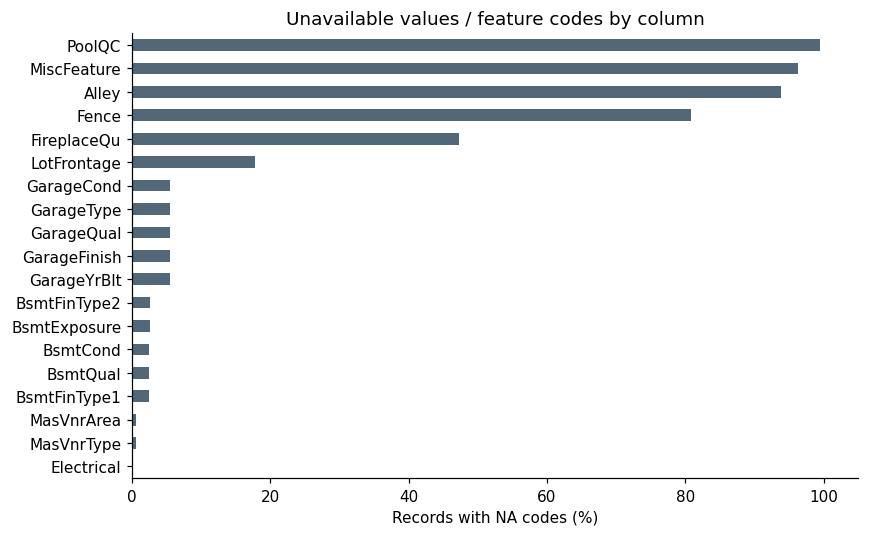

In [3]:
missing = pd.DataFrame({
    "NA codes": raw.eq("NA").sum(),
    "Blank strings": raw.eq("").sum(),
    "Unavailable in analysis": houses.isna().sum()
})
missing["Unavailable (%)"] = 100 * missing["Unavailable in analysis"] / len(houses)
missing = missing.loc[missing["Unavailable in analysis"] > 0].sort_values("Unavailable in analysis", ascending=False)
display(missing.round(2))
missing.to_csv(results_dir / "missing_values.csv")
fig, ax = plt.subplots(figsize=(8, 5))
missing["Unavailable (%)"].sort_values().plot.barh(ax=ax, color="#526778")
ax.set(xlabel="Records with NA codes (%)", title="Unavailable values / feature codes by column", xlim=(0, 105))
save_plot(fig, "01_missing_values")

## 3. Sale-price distribution
A histogram shows the overall shape. A log transformation is also shown because a few expensive homes can stretch the raw scale. All prices are positive, so the natural logarithm is defined. A less skewed log distribution is not by itself proof of normality.

,SalePrice
count,1460.0
mean,180921.2
std,79442.5
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


Price skewness: 1.883
Log-price skewness: 0.121


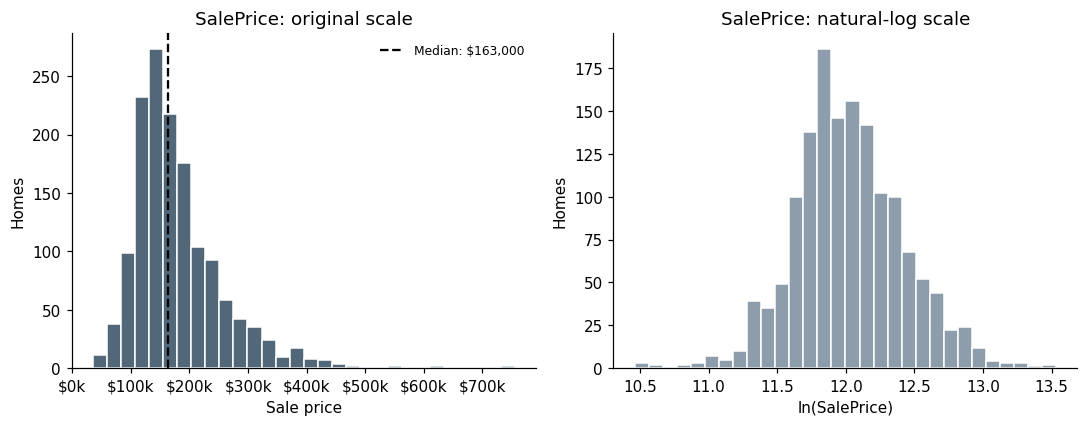

In [4]:
price = houses["SalePrice"]
log_price = np.log(price)
price_summary = price.describe().to_frame("SalePrice")
display(price_summary.round(2))
print(f"Price skewness: {price.skew():.3f}")
print(f"Log-price skewness: {log_price.skew():.3f}")
price_summary.to_csv(results_dir / "sale_price_summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(price, bins=30, color="#526778", edgecolor="white")
axes[0].axvline(price.median(), color="black", linestyle="--", label=f"Median: ${price.median():,.0f}")
axes[0].xaxis.set_major_formatter(money)
axes[0].set(title="SalePrice: original scale", xlabel="Sale price", ylabel="Homes")
axes[0].legend(frameon=False, fontsize=8)
axes[1].hist(log_price, bins=30, color="#8D9DAB", edgecolor="white")
axes[1].set(title="SalePrice: natural-log scale", xlabel="ln(SalePrice)", ylabel="Homes")
save_plot(fig, "02_price_distribution")

The mean price is **$180,921.20**, while the median is **$163,000**. The middle 50% ranges from **$129,975** to **$214,000** (IQR = $84,025). Prices range from **$34,900** to **$755,000**. The distribution is right-skewed: skewness is **1.883**, falling to **0.121** on the natural-log scale. This suggests that reporting the median and IQR is useful alongside the mean and standard deviation.

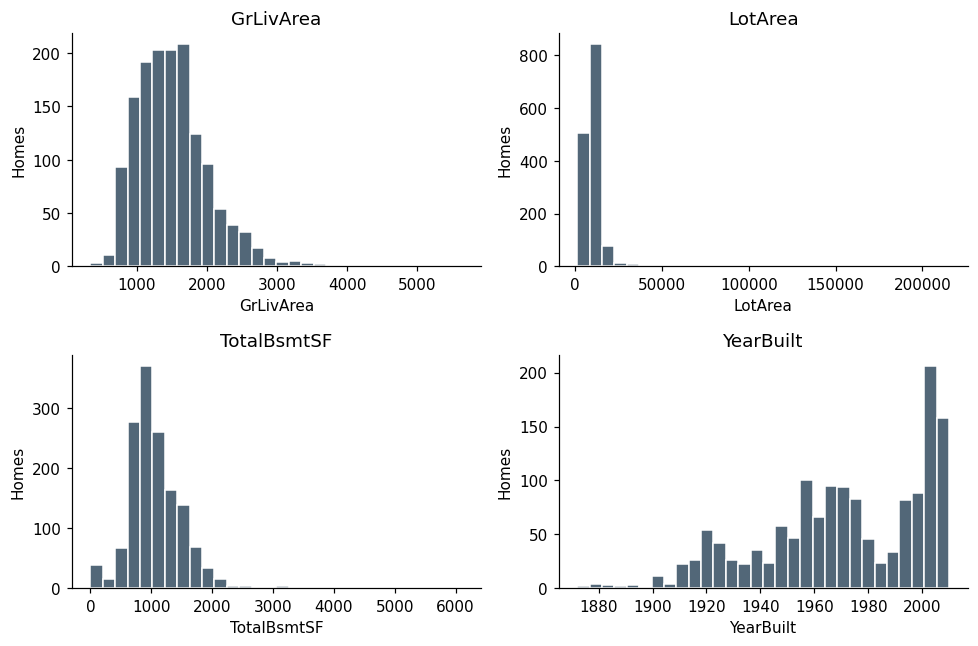

,Skewness
GrLivArea,1.367
LotArea,12.208
TotalBsmtSF,1.524
YearBuilt,-0.613


In [5]:
distribution_columns = ["GrLivArea", "LotArea", "TotalBsmtSF", "YearBuilt"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for column, ax in zip(distribution_columns, axes.flat):
    ax.hist(houses[column].dropna(), bins=30, color="#526778", edgecolor="white")
    ax.set(title=column, xlabel=column, ylabel="Homes")
save_plot(fig, "03_predictor_distributions")
display(houses[distribution_columns].skew().rename("Skewness").to_frame().round(3))

Living area and lot area have long right tails, so unusually large properties can influence correlations. YearBuilt is unevenly distributed across construction years. These variables do not all have the same shape as price, and correlation alone cannot describe their full relationship.

## 4. Correlations with sale price
I exclude `Id` (identifier), `MSSubClass` (category code), and `MoSold`/`YrSold` (sale-time codes with limited scope here) from the feature ranking. YearBuilt and YearRemodAdd remain because their numerical order has a useful interpretation. Pearson r describes linear association; Spearman rho describes rank association and is especially useful for the ordinal quality rating. This ranking is exploratory; no causal or predictive claims follow from it.

,Pearson r,Spearman rho,Pairs n
OverallQual,0.791,0.810,1460
GrLivArea,0.709,0.731,1460
GarageCars,0.640,0.691,1460
GarageArea,0.623,0.649,1460
TotalBsmtSF,0.614,0.603,1460
1stFlrSF,0.606,0.575,1460
FullBath,0.561,0.636,1460
TotRmsAbvGrd,0.534,0.533,1460
YearBuilt,0.523,0.653,1460
YearRemodAdd,0.507,0.571,1460


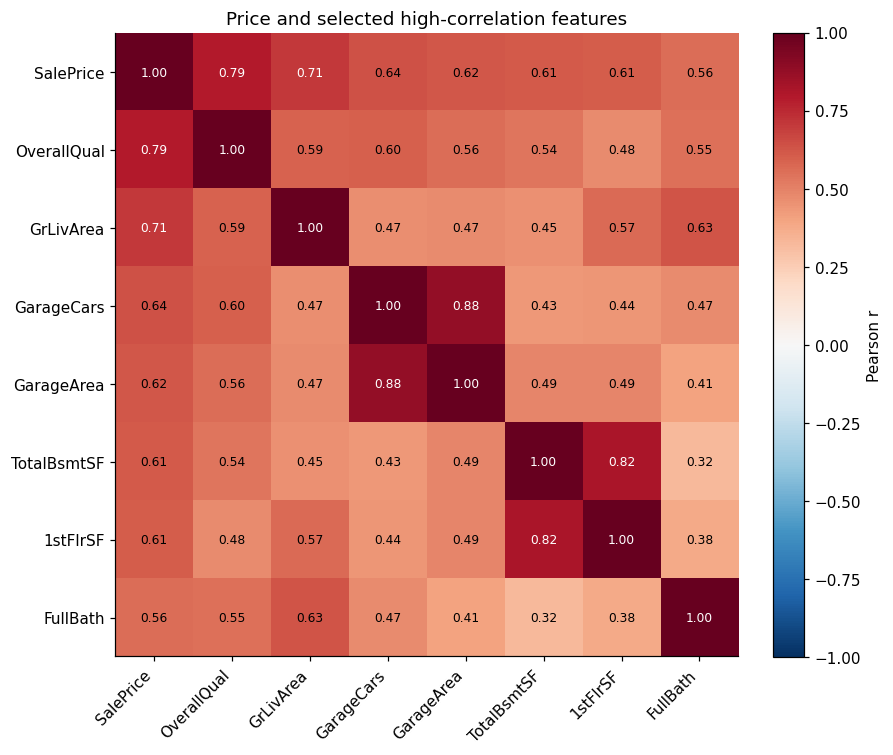

In [6]:
numeric = houses.select_dtypes(include="number")
feature_columns = numeric.columns.drop(["Id", "MSSubClass", "MoSold", "YrSold", "SalePrice"])
pearson = houses[feature_columns].corrwith(price, method="pearson")
spearman = houses[feature_columns].corrwith(price, method="spearman")
pair_counts = houses[feature_columns].notna().mul(price.notna(), axis=0).sum()
correlations = pd.DataFrame({"Pearson r": pearson, "Spearman rho": spearman, "Pairs n": pair_counts})
correlations = correlations.loc[correlations["Pearson r"].abs().sort_values(ascending=False).index]
display(correlations.head(12).round(3))
correlations.to_csv(results_dir / "price_correlations.csv")

heat_columns = ["SalePrice"] + correlations.head(7).index.tolist()
heat = houses[heat_columns].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(heat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(heat_columns)), heat_columns, rotation=45, ha="right")
ax.set_yticks(range(len(heat_columns)), heat_columns)
for i in range(len(heat_columns)):
    for j in range(len(heat_columns)):
        ax.text(j, i, f"{heat.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(heat.iloc[i,j]) > 0.65 else "black")
fig.colorbar(im, ax=ax, label="Pearson r", fraction=0.046)
ax.set_title("Price and selected high-correlation features")
save_plot(fig, "04_correlation_heatmap")

The largest Pearson correlations with SalePrice are **OverallQual (0.791)**, **GrLivArea (0.709)**, **GarageCars (0.640)**, **GarageArea (0.623)**, and **TotalBsmtSF (0.614)**. OverallQual also has a strong Spearman correlation (**0.810**), which supports a positive ordered association.

The heatmap also shows relationships between predictors. For example, garage capacity and garage area overlap conceptually. These correlations should not be treated as independent contributions to price, and I have not adjusted for neighbourhood or other variables.

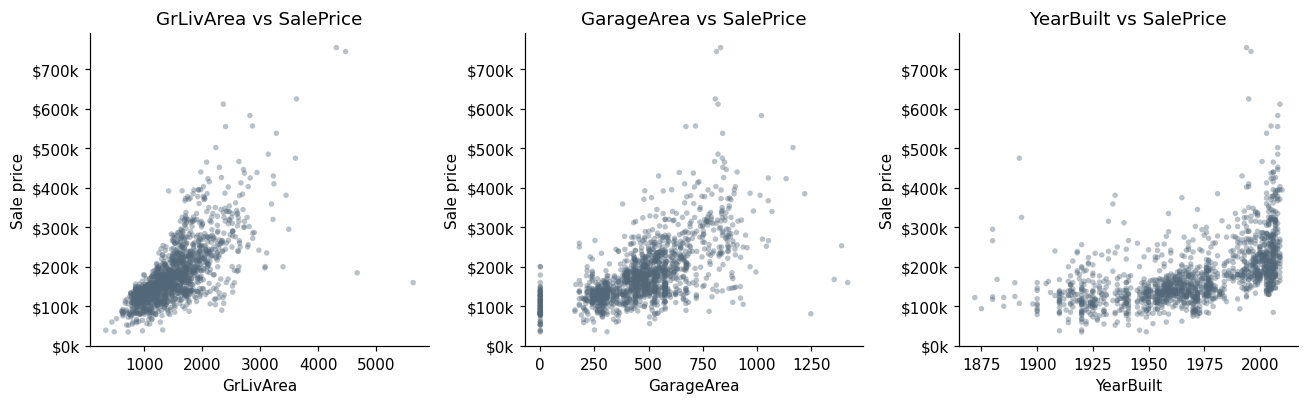

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for column, ax in zip(["GrLivArea", "GarageArea", "YearBuilt"], axes):
    ax.scatter(houses[column], price, s=13, alpha=0.4, color="#526778", edgecolors="none")
    ax.yaxis.set_major_formatter(money)
    ax.set(xlabel=column, ylabel="Sale price", title=f"{column} vs SalePrice")
save_plot(fig, "05_price_scatterplots")

Larger living areas, larger garages, and newer construction generally appear alongside higher prices, but there is substantial variation. A straight correlation does not capture every pattern, and a few very large homes sell below what the overall area-price trend might suggest.

## 5. Overall quality and neighbourhood
Boxplots compare medians, middle spreads, and extreme values across quality ratings. Neighbourhood medians describe group differences, with counts shown so very small groups are not given the same weight as large ones.

,count,median,mean
OverallQual,,,
1,2,50150.0,50150.00
2,3,60000.0,51770.33
3,20,86250.0,87473.75
4,116,108000.0,108420.66
5,397,133000.0,133523.35
6,374,160000.0,161603.03
7,319,200141.0,207716.42
8,168,269750.0,274735.54
9,43,345000.0,367513.02


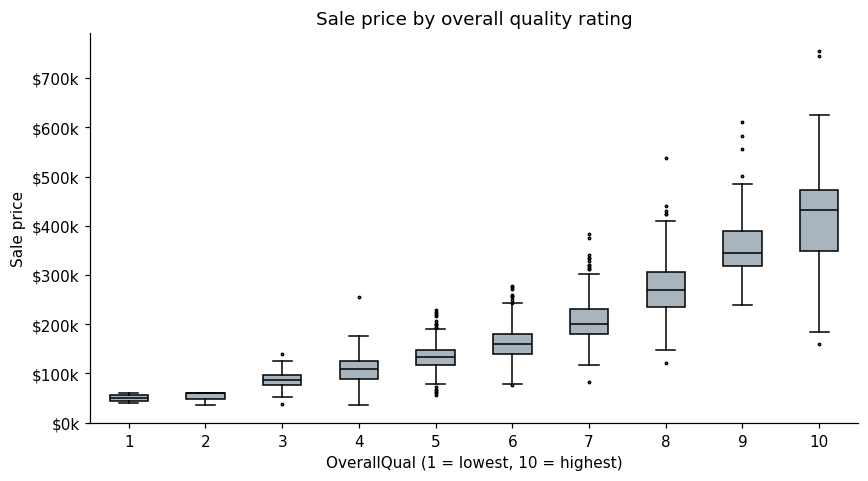

In [8]:
quality_summary = houses.groupby("OverallQual")["SalePrice"].agg(["count", "median", "mean"])
display(quality_summary.round(2))
quality_summary.to_csv(results_dir / "quality_summary.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
quality_levels = quality_summary.index.tolist()
ax.boxplot([houses.loc[houses["OverallQual"] == q, "SalePrice"] for q in quality_levels],
           tick_labels=[str(q) for q in quality_levels], patch_artist=True,
           boxprops={"facecolor": "#A8B5BF"}, medianprops={"color": "black"},
           flierprops={"marker": ".", "markersize": 3})
ax.set(xlabel="OverallQual (1 = lowest, 10 = highest)", ylabel="Sale price", title="Sale price by overall quality rating")
ax.yaxis.set_major_formatter(money)
save_plot(fig, "06_quality_boxplots")

Median price increases across the observed quality ratings: for example, **$133,000** at rating 5, **$200,141** at 7, and **$269,750** at 8. Ratings 1 and 2 contain only 2 and 3 houses, so their summaries are particularly uncertain. Higher ratings also have varying within-group spreads; the rating is associated with price but does not determine an exact value.

,count,median,mean
Neighborhood,,,
MeadowV,17,88000.0,98576.47
IDOTRR,37,103000.0,100123.78
BrDale,16,106000.0,104493.75
OldTown,113,119000.0,128225.30
Edwards,100,121750.0,128219.70
BrkSide,58,124300.0,124834.05
Sawyer,74,135000.0,136793.14
Blueste,2,137500.0,137500.00
SWISU,25,139500.0,142591.36


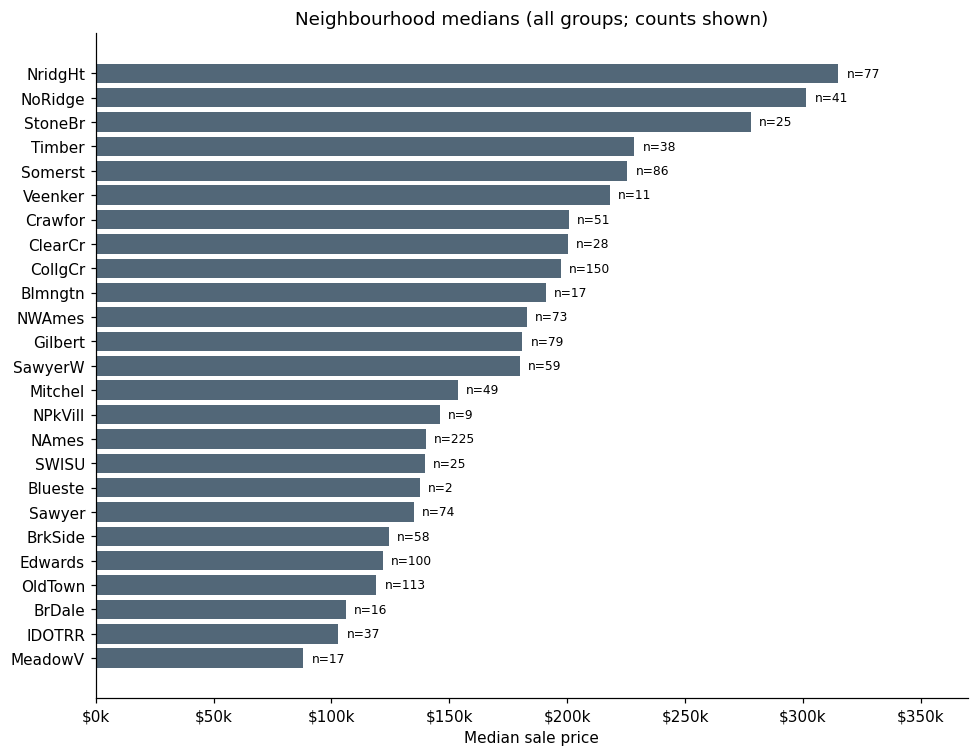

In [9]:
neighborhood_summary = houses.groupby("Neighborhood")["SalePrice"].agg(["count", "median", "mean"]).sort_values("median")
display(neighborhood_summary.round(2))
neighborhood_summary.to_csv(results_dir / "neighborhood_summary.csv")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(neighborhood_summary.index, neighborhood_summary["median"], color="#526778")
for i, (_, row) in enumerate(neighborhood_summary.iterrows()):
    ax.text(row["median"] + 3500, i, f"n={int(row['count'])}", va="center", fontsize=8)
ax.set(xlabel="Median sale price", title="Neighbourhood medians (all groups; counts shown)", xlim=(0, 370000))
ax.xaxis.set_major_formatter(money)
save_plot(fig, "07_neighborhood_medians")

Neighbourhood medians range from **$88,000 in MeadowV (n = 17)** to **$315,000 in NridgHt (n = 77)**. This is a descriptive comparison, not proof that location alone caused the price gap: neighbourhoods may also differ in house size, quality, and age. Some groups are small, including Blueste (n = 2), so their medians should be interpreted cautiously.

## 6. Extreme values and a sensitivity check
I use the conventional 1.5 x IQR rule to flag sale-price extremes. A flag does not prove a mistake. I retain every record in the main analysis, then compare the living-area correlation with and without homes above 4,000 square feet as a clearly labelled exploratory sensitivity check.

In [10]:
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
price_extremes = houses.loc[(price < lower_fence) | (price > upper_fence)]
print(f"IQR: ${iqr:,.0f}; fences: ${lower_fence:,.2f} to ${upper_fence:,.2f}")
print(f"Flagged sale prices: {len(price_extremes)} of {len(houses)} ({len(price_extremes)/len(houses):.2%})")
print("Flagged records are retained in the main analysis.")
display(houses.nlargest(5, "GrLivArea")[["Id", "GrLivArea", "OverallQual", "SalePrice"]])
full_r = houses["GrLivArea"].corr(price)
restricted = houses.loc[houses["GrLivArea"] <= 4000]
restricted_r = restricted["GrLivArea"].corr(restricted["SalePrice"])
sensitivity = pd.DataFrame({"Sample": ["All homes", "GrLivArea <= 4000 (sensitivity only)"],
                            "n": [len(houses), len(restricted)], "Pearson r": [full_r, restricted_r]})
display(sensitivity.round(4))
sensitivity.to_csv(results_dir / "area_sensitivity.csv", index=False)
price_extremes[["Id", "SalePrice", "GrLivArea", "OverallQual"]].to_csv(results_dir / "price_extremes.csv", index=False)

IQR: $84,025; fences: $3,937.50 to $340,037.50
Flagged sale prices: 61 of 1460 (4.18%)
Flagged records are retained in the main analysis.


,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000


,Sample,n,Pearson r
0,All homes,1460,0.7086
1,GrLivArea <= 4000 (sensitivity only),1456,0.7205


The upper price fence is **$340,037.50**, and **61 homes (4.18%)** are flagged; none falls below the lower fence. These may be legitimate high-value properties. Living-area Pearson r changes from **0.709** for all homes to **0.721** for homes at or below 4,000 square feet. The positive association remains, but the difference illustrates sensitivity to extremes. The threshold is exploratory, and no observations are removed from the main findings.

In [11]:
processed_dir = project_root / "Data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
houses.to_csv(processed_dir / "houses_analysis.csv", index=False)
assert houses.shape == (1460, 81)
assert houses["Id"].is_unique and price.notna().all() and (price > 0).all()
assert len(price_extremes) == 61
assert houses["SalePrice"].equals(raw["SalePrice"])
print("Checks passed: shape, unique IDs, complete positive prices, outlier count, and unchanged outcome.")

Checks passed: shape, unique IDs, complete positive prices, outlier count, and unchanged outcome.


## 7. Conclusion and limitations
The supplied house prices are right-skewed. The median and IQR describe a typical home more robustly than the mean alone, while log price is much more symmetric. Overall quality and above-ground living area have the strongest observed price associations in the numerical ranking. Garage size/capacity and basement area also correlate positively with price. Quality groups and neighbourhoods show clear descriptive price differences.

This is an exploratory study of the supplied training data. Correlations do not establish causation or independent effects. Ordinal and category codes need care, predictors overlap, missing/absent-feature codes require a dictionary, and unusual properties affect summaries. Group sizes differ, and neighbourhood characteristics may be confounded. There is no held-out evaluation, prediction model, or basis here for claiming future price accuracy. These findings should not be generalized to a different market or period without further evidence.

## 8. Submission and GitHub
Submit this notebook, the one-page PDF in `Docs`, and the actual GitHub repository link. The complete project ZIP has the requested folders and README.

**GitHub repository:** [https://github.com/somto436/house-prices-analysis](https://github.com/somto436/house-prices-analysis)

## Sources
- Supplied `train(2).csv`, the House Prices training data provided for this assignment. It is stored unchanged as `Data/raw/train.csv`.
- Assignment reference: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/code
- Supplied reading: *How to organize your Python data science project*.